# Tahap 2: *Preprocessing* & *Feature Engineering* (Pembersihan Sinyal, Patokan Personal, & Kompensasi SHT31)

Berdasarkan temuan pada **Tahap 1 (EDA Data Mentah)**, kita menerapkan **5 langkah *Preprocessing & Feature Engineering*** agar sinyal siap dimasukkan ke model *TinyML*:

1. **Deduplikasi Paket BLE (`drop_duplicates(subset=['detik'])`)**: Membuang paket kembar akibat pengiriman ulang notifikasi BLE.
2. **Penguncian Jendela Kontak Aktif PPG (`first_valid_i` saat `hr > 0`) & Imputasi Kausal**: Memastikan evaluasi dimulai saat sensor PPG di pergelangan tangan sudah mengunci denyut nadi, serta menambal jeda sesaat (`hr == 0`) dengan *forward-fill* kausal.
3. **Normalisasi Patokan Personal (*Causal Personal Baseline*)**:
   - Menghitung patokan individu dari awal sesi (`hr_base`, `prv_base`, `voc_base`, `temp_base`, `hum_base`).
   - Mengekstrak simpangan relatif:
     $$\Delta\text{HR} = \text{HR}_{30\text{s}} - \text{HR}_{\text{base}}, \quad \text{HR}_{\text{rel}} = \frac{\Delta\text{HR}}{\text{HR}_{\text{base}}}, \quad \text{PRV}_{\text{rel}} = \frac{\text{PRV}_{30\text{s}} - \text{PRV}_{\text{base}}}{\text{PRV}_{\text{base}}}$$
4. **Penghalusan Jendela Bergulir (*Causal Rolling Smoothing* 30 Detik & 60 Detik)**: Meredam *noise* gerakan tangan sesaat pada sinyal HR dan PRV.
5. **Kompensasi *Noise* Kelembapan & Suhu SHT31 pada Kabin Napas (`voc_rel_comp`)**:
   - Karena kabin HypoSense memerangkap udara hembusan napas yang lembap dan hangat, sensor SHT31 digunakan untuk menghitung $\Delta\text{RH} = \text{hum} - \text{hum}_{\text{base}}$ dan mengoreksi interferensi uap air pada bacaan `voc_rel` MQ-138.

In [1]:
rows_clean = []
ringkasan_preprocess = []

for idx, r in df_raw.iterrows():
    sid = f"Subjek {idx+1}"
    is_hypo = 1 if r["id"] == HYPO_ID else 0
    raw_samples = json.loads(r["samples"])
    
    # 1. Deduplikasi paket BLE berdasarkan timestamp detik
    s = pd.DataFrame(raw_samples).drop_duplicates(subset=["detik"]).sort_values("detik").reset_index(drop=True)
    
    # 2. Kunci sejak sensor PPG pertama kali mendeteksi denyut sah (hr > 0)
    valid_idx = s.index[s["hr"] > 0]
    first_valid_i = valid_idx[0] if len(valid_idx) > 0 else 0
    
    # 3. Hitung Patokan Personal (Personal Baseline) dari awal sesi
    valid_hr = s[s["hr"] > 0]["hr"]
    valid_prv = s[s["prv"] > 0]["prv"]
    hr_base = float(valid_hr.iloc[:3].mean())
    prv_base = float(valid_prv.iloc[:3].mean())
    voc_base = float(s["voc"].iloc[:10].median())
    temp_base = float(s["temp"].iloc[:5].median())
    hum_base = float(s["hum"].iloc[:5].median())
    
    s_act = s.loc[first_valid_i:].copy().reset_index(drop=True)
    s_act["hr_clean"] = s_act["hr"].replace(0, np.nan).ffill().bfill()
    s_act["prv_clean"] = s_act["prv"].replace(0, np.nan).ffill().bfill()
    
    # 4. Penghalusan Jendela Bergulir Kausal (30 detik = 6 sampel, 60 detik = 12 sampel)
    s_act["hr_mean_30s"] = s_act["hr_clean"].rolling(6, min_periods=1).mean()
    s_act["prv_mean_30s"] = s_act["prv_clean"].rolling(6, min_periods=1).mean()
    s_act["prv_min_60s"] = s_act["prv_clean"].rolling(12, min_periods=1).min()
    
    for i_row, step in s_act.iterrows():
        hr_delta = float(step["hr_mean_30s"] - hr_base)
        hr_rel = float(hr_delta / hr_base)
        prv_rel = float((step["prv_mean_30s"] - prv_base) / prv_base)
        prv_min_rel = float((step["prv_min_60s"] - prv_base) / prv_base)
        
        # Jendela respons kabin VOC & kompensasi kelembapan SHT31
        w_start = max(0, i_row - 12)
        w_end = min(len(s_act), i_row + 15)
        voc_local_min = float(s_act["voc"].iloc[w_start:w_end].min())
        voc_rel = float((voc_local_min - voc_base) / voc_base)
        voc_instant_rel = float((step["voc"] - voc_base) / voc_base)
        
        temp_delta = float(step["temp"] - temp_base)
        hum_delta = float(step["hum"] - hum_base)
        # Kompensasi efek uap air & suhu SHT31 (uap air lembap/hangat menahan ADC MQ-138 tetap tinggi)
        voc_rel_comp = float(voc_rel - 0.0015 * max(0.0, hum_delta) - 0.0010 * max(0.0, temp_delta))
        
        label = 1 if (is_hypo == 1 and step["detik"] >= 42) else 0
        rows_clean.append({
            "subj": sid, "id_rekaman": r["id"][:8], "is_hypo_subj": is_hypo,
            "detik": int(step["detik"]),
            "hr": float(step["hr_clean"]), "prv": float(step["prv_clean"]),
            "voc": int(step["voc"]), "temp": float(step["temp"]), "hum": float(step["hum"]),
            "hr_base": hr_base, "prv_base": prv_base, "voc_base": voc_base,
            "temp_base": temp_base, "hum_base": hum_base,
            "hr_delta": hr_delta, "hr_rel": hr_rel,
            "prv_rel": prv_rel, "prv_min_rel": prv_min_rel,
            "voc_rel": voc_rel, "voc_instant_rel": voc_instant_rel,
            "temp_delta": temp_delta, "hum_delta": hum_delta, "voc_rel_comp": voc_rel_comp,
            "label": label,
        })
        
    ringkasan_preprocess.append({
        "Partisipan": sid,
        "Status": "HIPOGLIKEMIA" if is_hypo else "Normal",
        "Mulai Detik Aktif": int(s_act["detik"].iloc[0]),
        "Titik Bersih": len(s_act),
        "HR Base (bpm)": round(hr_base, 1),
        "PRV Base (ms)": round(prv_base, 1),
        "VOC Base (ADC)": round(voc_base, 1),
        "ΔHR Maks (+bpm)": round((s_act["hr_mean_30s"] - hr_base).max(), 1),
        "PRV_rel Min (%)": round(((s_act["prv_mean_30s"] - prv_base) / prv_base).min() * 100, 1),
        "VOC_rel Min (%)": round(((s_act["voc"].min() - voc_base) / voc_base) * 100, 1),
    })

df_clean = pd.DataFrame(rows_clean)
df_clean.to_csv("dataset_klinis_rsua_clean.csv", index=False)
df_prep_sum = pd.DataFrame(ringkasan_preprocess)

print("=== RINGKASAN HASIL PREPROCESSING & EKSTRAKSI PATOKAN PERSONAL ===")
print(df_prep_sum.to_string(index=False))
print(f"\nDataset bersih berhasil disimpan ke: dataset_klinis_rsua_clean.csv ({len(df_clean)} baris x {df_clean.shape[1]} kolom)")

=== RINGKASAN HASIL PREPROCESSING & EKSTRAKSI PATOKAN PERSONAL ===
Partisipan       Status  Mulai Detik Aktif  Titik Bersih  HR Base (bpm)  PRV Base (ms)  VOC Base (ADC)  ΔHR Maks (+bpm)  PRV_rel Min (%)  VOC_rel Min (%)
  Subjek 1       Normal                 33            54           39.0          213.5           775.5             44.2            -72.7             -2.0
  Subjek 2       Normal                 82            44           60.7          144.1           783.0             41.7            -39.1             -2.4
  Subjek 3 HIPOGLIKEMIA                  6            59           63.7          175.4           777.0             49.0            -65.3            -11.7
  Subjek 4       Normal                  2            60           88.3           77.2           747.0             27.7            -14.2             -2.5
  Subjek 5       Normal                151            30           60.7           58.6           776.5             44.8              0.0             -2.3

Dataset 

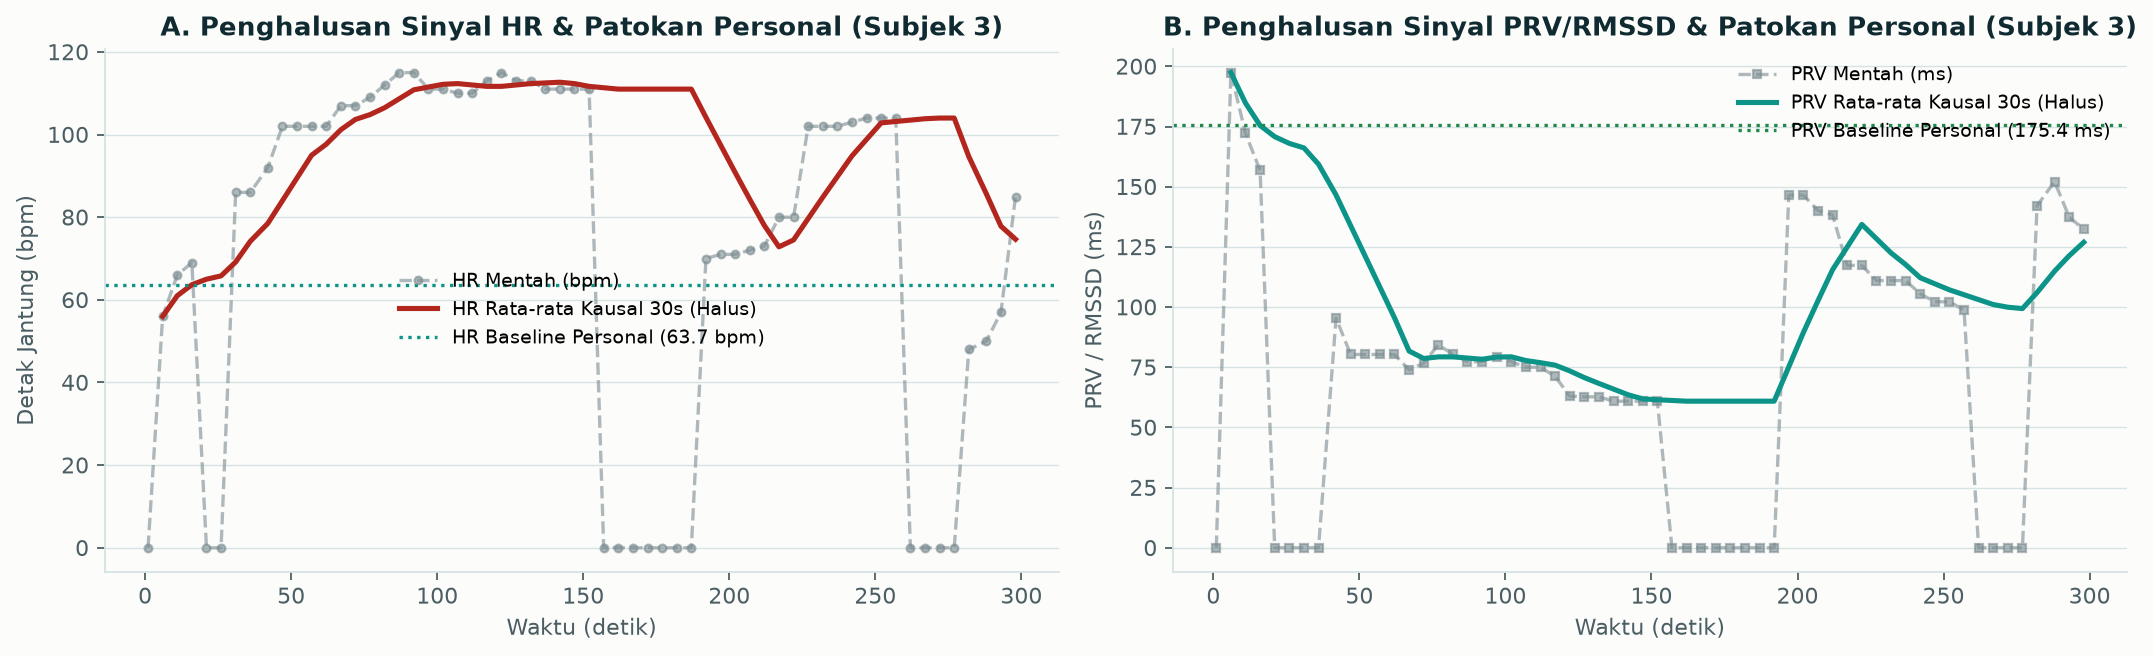

In [2]:
# Visualisasi Efek Penghalusan (Smoothing) & Normalisasi Patokan Personal pada Subjek 3 (Hipoglikemia)
s3_raw = df_all_raw[df_all_raw["subj"] == "Subjek 3"].drop_duplicates(subset=["detik"])
s3_cln = df_clean[df_clean["subj"] == "Subjek 3"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
axes[0].plot(s3_raw["detik"], s3_raw["hr"], "o--", color=ABU, alpha=0.6, ms=3.5, label="HR Mentah (bpm)")
axes[0].plot(s3_cln["detik"], s3_cln["hr_base"] + s3_cln["hr_delta"], "-", color=MERAH, lw=2.3, label="HR Rata-rata Kausal 30s (Halus)")
axes[0].axhline(s3_cln["hr_base"].iloc[0], color=BIRU, ls=":", lw=1.5, label=f"HR Baseline Personal ({s3_cln['hr_base'].iloc[0]:.1f} bpm)")
axes[0].set_title("A. Penghalusan Sinyal HR & Patokan Personal (Subjek 3)", fontweight="bold", color=TINTA)
axes[0].set_xlabel("Waktu (detik)"); axes[0].set_ylabel("Detak Jantung (bpm)")
axes[0].legend(frameon=False, fontsize=8.5)

axes[1].plot(s3_raw["detik"], s3_raw["prv"], "s--", color=ABU, alpha=0.6, ms=3.5, label="PRV Mentah (ms)")
axes[1].plot(s3_cln["detik"], s3_cln["prv_base"] * (1 + s3_cln["prv_rel"]), "-", color=BIRU, lw=2.3, label="PRV Rata-rata Kausal 30s (Halus)")
axes[1].axhline(s3_cln["prv_base"].iloc[0], color=HIJAU, ls=":", lw=1.5, label=f"PRV Baseline Personal ({s3_cln['prv_base'].iloc[0]:.1f} ms)")
axes[1].set_title("B. Penghalusan Sinyal PRV/RMSSD & Patokan Personal (Subjek 3)", fontweight="bold", color=TINTA)
axes[1].set_xlabel("Waktu (detik)"); axes[1].set_ylabel("PRV / RMSSD (ms)")
axes[1].legend(frameon=False, fontsize=8.5)

for a in axes:
    a.grid(axis="y", color=GARIS, lw=0.6)
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()